# 03 - Forecasting Monthly Tourist Demand
**Task:** predict the number of tourists for each destination and tourist type
**one month ahead** (regression, supervised learning).

* **Unit of prediction:** one series-month, e.g. *Domestic | Abha | July 2025*.
* **Target y:** number of overnight tourists (modelled as `log(1 + tourists)`).
* **Inputs X:** only information available at the end of the previous month:
  past values (lags), calendar (month, Ramadan / Hajj days - published in advance),
  tourist type, province.
* **Setting:** *rolling one-month-ahead* forecasting - when we forecast month t,
  the real values up to month t-1 are already known. This is **not** a forecast
  of a whole year in advance.

**Models compared** (chosen so that every step can be explained with CS316 material):
1. **Previous-month baseline** - no learning, "next month = this month".
2. **Linear Regression** - the course's main regression model.
3. **Linear Regression with PCA** - the course's dimensionality-reduction method before the regression.
4. **Random Forest Regression** - one extra, non-linear model (the only method beyond the slides).

Course topics: statistical learning (train / validation / test), regression,
MSE/RMSE/MAE, overfitting, standardisation, one-hot encoding, PCA, gradient descent.

## 0. Setup (works in Google Colab and on a local computer)

**Google Colab:** run the cell below. It downloads the project from GitHub
(set `REPO_URL` to your repository). If you do not use GitHub, upload the
whole `CS316_Tourism_Project` folder to Google Drive instead and set
`DRIVE_PATH`; the cell will mount Drive and use that folder.

**Locally:** just run the cell; it finds the project folder automatically.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/<your-username>/CS316_Tourism_Project.git"  # <- edit
DRIVE_PATH = "/content/drive/MyDrive/CS316_Tourism_Project"                # <- or edit

if "google.colab" in sys.modules:                      # running inside Colab
    if "<your-username>" not in REPO_URL:              # option A: clone from GitHub
        if not Path("/content/CS316_Tourism_Project").exists():
            subprocess.run(["git", "clone", REPO_URL, "/content/CS316_Tourism_Project"], check=True)
        os.chdir("/content/CS316_Tourism_Project")
    else:                                              # option B: Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir(DRIVE_PATH)
elif Path.cwd().name == "notebooks":                   # local run from notebooks/
    os.chdir("..")

PROJECT = Path.cwd()                                   # project root folder
sys.path.insert(0, str(PROJECT / "src"))               # so we can `import tourism`
FIG = PROJECT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = PROJECT / "outputs"
print("Project folder:", PROJECT)

Project folder: /home/user/CS316_Tourism_Project


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import tourism as t

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
SEED = 42                                    # fixed seed -> reproducible results

## 1. Build the modelling table
`t.build_features` (in `src/tourism.py`) keeps the 52 fully observed series and
creates the features below. All count features are on the log scale.

| Feature | Meaning | Why it can help |
|---|---|---|
| `lag1`, `lag2`, `lag3` | tourists 1, 2, 3 months ago | recent level |
| `lag12`, `lag13`, `lag14`, `lag15` | same month (and neighbours) last year | seasonality |
| `yoy1..3`, `yoy_mean3` | recent growth vs. last year (log ratio) | trend |
| `seasonal_step` | change from month t-1 to t **last year** | expected seasonal jump |
| `roll3` | mean of the last 3 months | smoothed level |
| `month_sin`, `month_cos` | month on a circle | Dec is next to Jan |
| `ramadan_days`, `hajj_days`, `prehajj_days` (+ `_change` vs last year) | days of each religious period in the month | the Hijri calendar moves ~11 days per year |
| `holy_*_change` | the changes above, only for Makkah & Madinah provinces | pilgrimage effects are local |
| `is_inbound`, `is_other`, `province` | categories (province is one-hot encoded) | different behaviour per group |

The first rows of every series do not have 15 months of history, so modelling
starts in **April 2022** (rows with missing lags are dropped, not imputed).

In [3]:
dests, _ = t.load_tourism()
feat = t.build_features(dests)
FEATURES = t.FEATURES_ALL
data = feat.dropna(subset=FEATURES).reset_index(drop=True)
print("Modelling rows:", len(data), "| series:", data.series.nunique(),
      "| months:", data.date.min().date(), "to", data.date.max().date())

Modelling rows: 2340 | series: 52 | months: 2022-04-01 to 2025-12-01


**Leakage checks.** (1) No feature may contain the current month's value.
(2) `lag1` must equal last month's real value of the same series.

In [4]:
assert not {"log_y", "tourists", "spending_sar"} & set(FEATURES)
chk = feat.sort_values(["series", "date"])
prev = chk.groupby("series")["log_y"].shift(1)
assert np.allclose(chk["lag1"].dropna(), prev.dropna())
print("Leakage checks passed: features use only previous months.")

Leakage checks passed: features use only previous months.


## 2. Time-aware data split and cross-validation
Random K-fold would train on 2025 and test on 2023 - using the future to predict
the past. Instead we use **expanding-window cross-validation**:

| Fold | Train on | Validate on |
|---|---|---|
| 1 | Apr 2022 - Dec 2022 | Jan - Jun 2023 |
| 2 | Apr 2022 - Jun 2023 | Jul - Dec 2023 |
| 3 | Apr 2022 - Dec 2023 | Jan - Jun 2024 |
| 4 | Apr 2022 - Jun 2024 | Jul - Dec 2024 |
| **Final test** | Apr 2022 - Dec 2024 | **Jan - Dec 2025 (never used for any decision)** |

Folds 3-4 together are the "validation year 2024". All learned preprocessing
(scaler, one-hot encoder, PCA) lives inside a scikit-learn `Pipeline`, so it is
re-fitted on the training part of every fold only.

Development rows: 1716 | Test rows (2025): 624


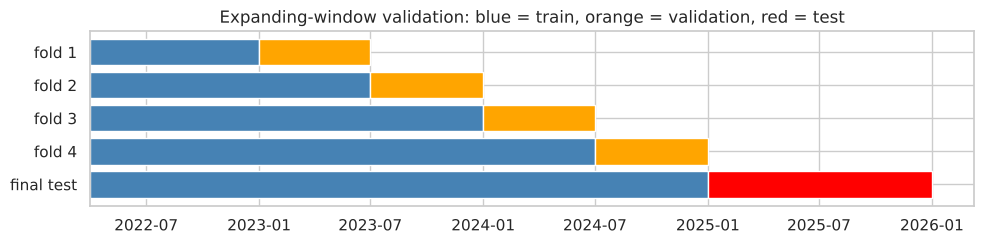

In [5]:
FOLDS = [("2023-01-01", "2023-07-01"), ("2023-07-01", "2024-01-01"),
         ("2024-01-01", "2024-07-01"), ("2024-07-01", "2025-01-01")]
TEST_START = "2025-01-01"
test = data[data.date >= TEST_START]
dev = data[data.date < TEST_START]          # development data (train + validation)
print("Development rows:", len(dev), "| Test rows (2025):", len(test))

fig, ax = plt.subplots(figsize=(10, 2.6))
for i, (a, b) in enumerate(FOLDS + [(TEST_START, "2026-01-01")]):
    ax.barh(i, pd.Timestamp(a) - pd.Timestamp("2022-04-01"), left=pd.Timestamp("2022-04-01"), color="steelblue")
    ax.barh(i, pd.Timestamp(b) - pd.Timestamp(a), left=pd.Timestamp(a), color="red" if i == 4 else "orange")
ax.set_yticks(range(5), ["fold 1", "fold 2", "fold 3", "fold 4", "final test"]); ax.invert_yaxis()
ax.set_title("Expanding-window validation: blue = train, orange = validation, red = test")
plt.tight_layout(); plt.savefig(FIG / "03_cv_scheme.png", dpi=200); plt.show()

## 3. Evaluation metrics
Errors are computed on the **original scale (tourists)** after converting the
log predictions back with `exp(x) - 1`.
* **MAE** - average absolute error (tourists). **RMSE** - like MAE but large misses count more.
* **WAPE** = sum|error| / sum(actual) x 100: the percentage of all tourists that were mis-forecast.
  Its denominator is large and never 0 here, so it is well defined (unlike MAPE, which
  explodes for tiny destinations).
* **Forecast accuracy = 100% - WAPE.** This is our answer to the rubric's
  "accuracy >= 80%" criterion. It is **not** classification accuracy: it means
  "the share of tourists that the forecast got right". **Main selection metric: CV WAPE.**
* **R2** - share of variance explained (interpret with care: big destinations dominate).

In [6]:
def preprocessor(features, scale=True):
    """Numeric features (optionally standardised) + one-hot encoded province.

    StandardScaler: (x - mean) / std, with mean and std learned from the TRAINING rows only.
    OneHotEncoder: turns the province name into 0/1 columns (one per province).
    """
    num = [c for c in features if c != "province"]
    steps = [("num", StandardScaler() if scale else "passthrough", num)]
    if "province" in features:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["province"]))
    return ColumnTransformer(steps)

def make_pipeline(estimator, features, scale=True, pca=None):
    """Preprocessing -> (optional PCA) -> model, all fitted together on training data only."""
    steps = [("prep", preprocessor(features, scale))]
    if pca is not None:
        steps.append(("pca", PCA(n_components=pca, random_state=SEED)))
    steps.append(("model", estimator))
    return Pipeline(steps)

def fit_predict(spec, train, valid):
    """Fit one model specification on `train`; return predicted tourist counts for `valid`."""
    if spec["kind"] == "baseline":                     # no fitting needed
        return np.expm1(valid["lag1"].to_numpy())      # tourists of the previous month
    pipe = make_pipeline(spec["estimator"](), spec["features"], spec.get("scale", True), spec.get("pca"))
    pipe.fit(train[spec["features"]], train["log_y"])  # target y = log(1 + tourists)
    return np.expm1(pipe.predict(valid[spec["features"]]))   # back to tourist counts

def cross_validate(spec):
    """Expanding-window CV: train on everything before each block, validate on the block."""
    out = []
    for i, (a, b) in enumerate(FOLDS, 1):
        tr = dev[dev.date < a]                          # past only
        va = dev[(dev.date >= a) & (dev.date < b)]      # the next half-year
        out.append(va[["series", "tourist_type", "date", "tourists"]]
                   .assign(pred=fit_predict(spec, tr, va), fold=i))
    return pd.concat(out)

SPECS, CV_PREDS, ROWS = {}, {}, []
def evaluate(name, spec, family, complexity, note=""):
    """Run CV for one configuration, then store and print its validation metrics."""
    P = cross_validate(spec); CV_PREDS[name] = P; SPECS[name] = spec
    m = t.regression_metrics(P.tourists, P.pred)                        # all 4 folds together
    v24 = P[P.fold >= 3]; m24 = t.regression_metrics(v24.tourists, v24.pred)   # 2024 only
    folds = P.groupby("fold").apply(lambda g: t.regression_metrics(g.tourists, g.pred)["WAPE_%"])
    ROWS.append({"model": name, "family": family, "complexity": complexity, "note": note,
                 "CV_WAPE_%": m["WAPE_%"], "CV_MAE": m["MAE"], "CV_RMSE": m["RMSE"], "CV_R2": m["R2"],
                 "Val2024_WAPE_%": m24["WAPE_%"], **{f"fold{k}_WAPE_%": v for k, v in folds.items()}})
    print(f"{name:52s} CV WAPE {m['WAPE_%']:6.2f}% | 2024 {m24['WAPE_%']:6.2f}% | folds {np.round(folds.values, 1)}")

## 4. Baseline: previous month
**What it does:** predicts that next month will have exactly as many tourists as this month.

**Why we need it:** it costs nothing and needs no learning. A machine-learning model is
only worth using if it clearly beats this simple rule on the same validation months.

In [7]:
evaluate("Baseline: previous month", {"kind": "baseline"}, "Previous-month baseline", 0)

Baseline: previous month                             CV WAPE  26.81% | 2024  25.78% | folds [30.8 25.  27.7 23.6]


## 5. Linear Regression
**How it works:** the model assumes
`log(tourists) = b0 + b1*x1 + b2*x2 + ... + error` and chooses the weights b that make the
**mean squared error** on the training data as small as possible (least squares).
Each weight says how much the prediction changes when that feature increases.

**Why we selected it:** it is the main regression model of the course, it is fast and
every coefficient can be interpreted. On the log scale it can express rules like
"same month last year x recent growth".

**Standardisation:** inputs are standardised (mean 0, std 1) using training statistics.
For plain Linear Regression this does not change the predictions, but it makes the
coefficients comparable and it is required for PCA in the next section.

**Feature-group experiment:** more features are not automatically better - extra
features can make the model fit noise (overfitting). We compare five groups on validation data.

In [8]:
GROUPS = {"basic lags": t.FEATURES_BASIC,
          "all lags": t.FEATURES_LAGS,
          "lags + holy-city calendar": t.FEATURES_LAGS + t.FEATURES_HOLY,
          "lags + calendar": t.FEATURES_LAGS + t.FEATURES_CAL,
          "all features": t.FEATURES_ALL}
for g, cols in GROUPS.items():
    evaluate(f"Linear Regression [{g}]",
             {"kind": "ml", "estimator": LinearRegression, "features": cols},
             "Linear Regression", 1, f"{len(cols)} inputs")

Linear Regression [basic lags]                       CV WAPE  25.98% | 2024  23.19% | folds [32.5 25.4 27.1 18.9]
Linear Regression [all lags]                         CV WAPE  24.42% | 2024  22.44% | folds [27.6 25.5 24.1 20.6]
Linear Regression [lags + holy-city calendar]        CV WAPE  24.58% | 2024  22.93% | folds [28.2 24.5 24.8 20.9]


Linear Regression [lags + calendar]                  CV WAPE  34.10% | 2024  29.63% | folds [48.6 29.1 36.3 22.3]


Linear Regression [all features]                     CV WAPE  35.17% | 2024  30.73% | folds [50.5 29.3 39.3 21.2]


## 6. Linear Regression with PCA
**How PCA works:** our lag features are strongly correlated (e.g. `lag12`, `lag13` and
`roll3` carry similar information). PCA rotates the standardised features into new,
**uncorrelated** directions (principal components) ordered by how much variance they
explain. We keep only the first components that together explain 80/90/95/99% of the
variance and give those to Linear Regression.

**Why we try it:** fewer, uncorrelated inputs can make Linear Regression more stable and
less prone to overfitting. It can also discard useful information, so we test it.

**No leakage:** the scaler and PCA are fitted on the training part of each fold only
(inside the `Pipeline`). The target is never given to PCA.

In [9]:
PCA_GROUPS = {"lags + holy-city calendar": t.FEATURES_LAGS + t.FEATURES_HOLY,
              "all features": t.FEATURES_ALL}
for g, cols in PCA_GROUPS.items():
    for v in [0.80, 0.90, 0.95, 0.99]:
        evaluate(f"PCA ({v:.0%} variance) + Linear Regression [{g}]",
                 {"kind": "ml", "estimator": LinearRegression, "features": cols, "pca": v},
                 "Linear Regression + PCA", 2, f"{g}")
# Normalisation experiment: PCA on UNscaled features (large-valued features dominate the variance)
evaluate("PCA (90% variance) + Linear Regression [lags + holy-city, NO scaling]",
         {"kind": "ml", "estimator": LinearRegression, "features": t.FEATURES_LAGS + t.FEATURES_HOLY,
          "pca": 0.90, "scale": False},
         "Linear Regression + PCA", 2, "normalisation experiment")

PCA (80% variance) + Linear Regression [lags + holy-city calendar] CV WAPE  23.86% | 2024  22.06% | folds [27.6 23.9 22.9 21.2]


PCA (90% variance) + Linear Regression [lags + holy-city calendar] CV WAPE  23.66% | 2024  23.10% | folds [26.7 21.9 24.3 21.7]
PCA (95% variance) + Linear Regression [lags + holy-city calendar] CV WAPE  23.79% | 2024  23.39% | folds [26.5 21.9 24.9 21.8]


PCA (99% variance) + Linear Regression [lags + holy-city calendar] CV WAPE  23.81% | 2024  22.75% | folds [28.  21.9 24.7 20.6]


PCA (80% variance) + Linear Regression [all features] CV WAPE  26.34% | 2024  27.80% | folds [23.9 25.7 33.  22.1]


PCA (90% variance) + Linear Regression [all features] CV WAPE  26.83% | 2024  28.08% | folds [23.6 27.4 34.9 20.5]


PCA (95% variance) + Linear Regression [all features] CV WAPE  27.04% | 2024  27.43% | folds [25.4 27.9 32.5 21.8]


PCA (99% variance) + Linear Regression [all features] CV WAPE  27.36% | 2024  27.23% | folds [27.2 27.8 33.5 20.3]
PCA (90% variance) + Linear Regression [lags + holy-city, NO scaling] CV WAPE  23.44% | 2024  21.82% | folds [26.4 24.  22.1 21.5]


80% of the variance -> 4 of 16 components
90% of the variance -> 6 of 16 components
95% of the variance -> 8 of 16 components
99% of the variance -> 9 of 16 components


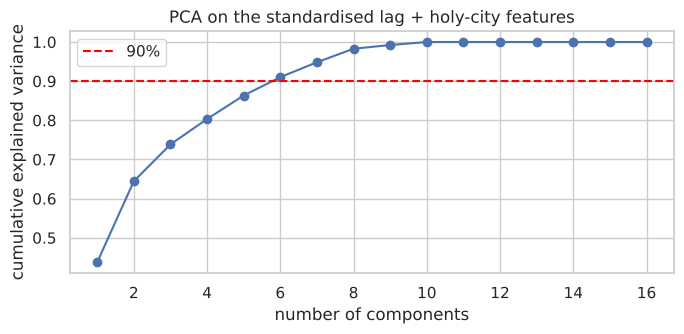

In [10]:
# How many components are needed? (scaler + PCA fitted on the 2022-2023 training part only)
cols = t.FEATURES_LAGS + t.FEATURES_HOLY
train_part = dev[dev.date < "2024-01-01"]
Z = preprocessor(cols).fit_transform(train_part[cols])
cum = np.cumsum(PCA(random_state=SEED).fit(Z).explained_variance_ratio_)
for v in [0.80, 0.90, 0.95, 0.99]:
    print(f"{v:.0%} of the variance -> {np.argmax(cum >= v) + 1} of {len(cum)} components")
plt.figure(figsize=(7, 3.5)); plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.90, color="red", ls="--", label="90%"); plt.legend()
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance")
plt.title("PCA on the standardised lag + holy-city features"); plt.tight_layout()
plt.savefig(FIG / "03_pca_variance.png", dpi=200); plt.show()

## 7. Random Forest Regression (the one model beyond the course slides)
**How it works:** a *decision tree* predicts by asking yes/no questions about the
features (e.g. "is `lag12` > 11.5?") and averaging the training targets in the final
leaf. One tree overfits easily. A **Random Forest** trains many trees (here 300), each
on a random bootstrap sample of the rows and using a random subset of features at each
split, and **averages** their predictions. Averaging many different trees reduces variance.

**Why we selected it:** tourism patterns are not purely linear - e.g. Ramadan matters
for Makkah but not for Abha. Trees learn such interactions automatically.

**Hyperparameters we tune on validation data:**
* `min_samples_leaf` - minimum rows in a leaf (larger = smoother trees, less overfitting).
* `max_features=0.5` - each split considers a random half of the features.

Trees split on the *order* of values, so they do not need standardisation.
Limitation: a tree cannot predict outside the range of values it saw in training.

In [11]:
for g, cols in [("lags + holy-city calendar", t.FEATURES_LAGS + t.FEATURES_HOLY),
                ("all features", t.FEATURES_ALL)]:
    for leaf in [2, 5, 10]:
        evaluate(f"Random Forest leaf={leaf} [{g}]",
                 {"kind": "ml", "features": cols, "scale": False,
                  "estimator": lambda leaf=leaf: RandomForestRegressor(
                      n_estimators=300, min_samples_leaf=leaf, max_features=0.5,
                      n_jobs=-1, random_state=SEED)},
                 "Random Forest", 3, g)

Random Forest leaf=2 [lags + holy-city calendar]     CV WAPE  24.17% | 2024  20.01% | folds [31.4 25.8 22.3 17.4]


Random Forest leaf=5 [lags + holy-city calendar]     CV WAPE  24.66% | 2024  20.76% | folds [31.8 25.8 23.  18.3]


Random Forest leaf=10 [lags + holy-city calendar]    CV WAPE  25.05% | 2024  21.91% | folds [31.8 25.  24.2 19.3]


Random Forest leaf=2 [all features]                  CV WAPE  22.91% | 2024  18.48% | folds [30.9 24.3 20.7 16. ]


Random Forest leaf=5 [all features]                  CV WAPE  23.58% | 2024  19.69% | folds [31.2 24.3 22.  17.2]


Random Forest leaf=10 [all features]                 CV WAPE  24.55% | 2024  21.21% | folds [31.9 24.3 23.6 18.5]


## 8. Model selection (decided on validation data only)
**Rule (fixed before looking at the test year):**
1. Within each family we keep the configuration with the lowest cross-validated WAPE.
2. The final model is the family winner with the lowest CV WAPE. If another family
   winner is within **0.5 percentage points**, we prefer the simpler model
   (baseline < Linear Regression < Linear Regression + PCA < Random Forest).

In [12]:
cv_table = pd.DataFrame(ROWS).sort_values("CV_WAPE_%").reset_index(drop=True)
cv_table.to_csv(OUT / "cv_results_all_models.csv", index=False)
finalists = cv_table.loc[cv_table.groupby("family")["CV_WAPE_%"].idxmin()].sort_values("CV_WAPE_%")
best_wape = finalists["CV_WAPE_%"].min()
near = finalists[finalists["CV_WAPE_%"] <= best_wape + 0.5]
SELECTED = near.sort_values(["complexity", "CV_WAPE_%"]).iloc[0]["model"]
print("Best configuration of each family:")
print(finalists[["model", "CV_WAPE_%", "Val2024_WAPE_%", "CV_MAE", "CV_RMSE", "CV_R2"]].round(2).to_string(index=False))
print("\nSELECTED MODEL:", SELECTED)
cv_table[["model", "CV_WAPE_%", "Val2024_WAPE_%", "fold1_WAPE_%", "fold2_WAPE_%",
          "fold3_WAPE_%", "fold4_WAPE_%"]].round(2)

Best configuration of each family:
                                                                model  CV_WAPE_%  Val2024_WAPE_%   CV_MAE   CV_RMSE  CV_R2
                                  Random Forest leaf=2 [all features]      22.91           18.48 40871.19 101877.83   0.86
PCA (90% variance) + Linear Regression [lags + holy-city, NO scaling]      23.44           21.82 41825.75  93827.76   0.88
                                         Linear Regression [all lags]      24.42           22.44 43575.67  98766.71   0.87
                                             Baseline: previous month      26.81           25.78 47829.42 118712.40   0.82

SELECTED MODEL: Random Forest leaf=2 [all features]


,model,CV_WAPE_%,Val2024_WAPE_%,fold1_WAPE_%,fold2_WAPE_%,fold3_WAPE_%,fold4_WAPE_%
0,Random Forest leaf=2 [all features],22.91,18.48,30.90,24.33,20.73,15.99
1,PCA (90% variance) + Linear Regression [lags +...,23.44,21.82,26.35,23.97,22.13,21.48
2,Random Forest leaf=5 [all features],23.58,19.69,31.15,24.30,21.96,17.17
3,PCA (90% variance) + Linear Regression [lags +...,23.66,23.10,26.67,21.87,24.35,21.71
4,PCA (95% variance) + Linear Regression [lags +...,23.79,23.39,26.52,21.94,24.85,21.76
5,PCA (99% variance) + Linear Regression [lags +...,23.81,22.75,27.98,21.91,24.72,20.56
6,PCA (80% variance) + Linear Regression [lags +...,23.86,22.06,27.63,23.93,22.85,21.17
7,Random Forest leaf=2 [lags + holy-city calendar],24.17,20.01,31.40,25.78,22.31,17.45
8,Linear Regression [all lags],24.42,22.44,27.57,25.50,24.11,20.57
9,Random Forest leaf=10 [all features],24.55,21.21,31.94,24.30,23.64,18.51


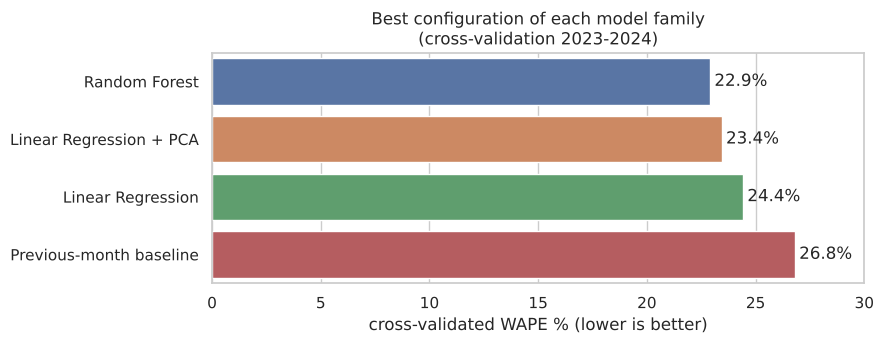

In [13]:
plt.figure(figsize=(9, 3.6))
sns.barplot(data=finalists, y="family", x="CV_WAPE_%", hue="family", dodge=False, legend=False)
for i, v in enumerate(finalists["CV_WAPE_%"]):          # write the value next to each bar
    plt.text(v + 0.2, i, f"{v:.1f}%", va="center")
plt.xlabel("cross-validated WAPE % (lower is better)"); plt.ylabel(""); plt.xlim(0, 30)
plt.title("Best configuration of each model family\n(cross-validation 2023-2024)")
plt.tight_layout(); plt.savefig(FIG / "03_cv_comparison.png", dpi=200); plt.show()

## 9. Final test on 2025 (used once)
The best configuration of each family is re-fitted on **all development data
(Apr 2022 - Dec 2024)** and predicts every month of 2025 one month ahead (using the real
values of earlier months as lag inputs). The models are **not** re-fitted during 2025.
We also compute the **training** error: a model whose training error is much lower than its
test error is overfitting.

In [14]:
TEST_PREDS, TRAIN_WAPE = {}, {}
for name in finalists["model"]:
    TEST_PREDS[name] = test[["series", "tourist_type", "destination", "date", "tourists"]].assign(
        pred=fit_predict(SPECS[name], dev, test))
    TRAIN_WAPE[name] = t.regression_metrics(dev.tourists, fit_predict(SPECS[name], dev, dev))["WAPE_%"]

def summary(P):
    """Destination-level and national-level metrics for one model's 2025 predictions."""
    d = t.regression_metrics(P.tourists, P.pred)
    nat = P.groupby(["tourist_type", "date"])[["tourists", "pred"]].sum()
    n = t.regression_metrics(nat.tourists, nat.pred)
    return {"Test_WAPE_%": d["WAPE_%"], "Test_Accuracy_%": d["Accuracy_%"], "Test_MAE": d["MAE"],
            "Test_RMSE": d["RMSE"], "Test_R2": d["R2"], "Test_MAPE_%": d["MAPE_%"],
            "National_WAPE_%": n["WAPE_%"], "National_Accuracy_%": n["Accuracy_%"]}

test_table = pd.DataFrame([{"model": k, "Train_WAPE_%": TRAIN_WAPE[k], **summary(v)}
                           for k, v in TEST_PREDS.items()])
comparison = finalists[["model", "family", "CV_WAPE_%", "Val2024_WAPE_%", "CV_MAE", "CV_RMSE", "CV_R2"]] \
    .merge(test_table, on="model")
comparison["selected"] = comparison["model"] == SELECTED
comparison.to_csv(OUT / "model_comparison.csv", index=False)
comparison.drop(columns=["family"]).round(2)

,model,CV_WAPE_%,Val2024_WAPE_%,CV_MAE,CV_RMSE,CV_R2,Train_WAPE_%,Test_WAPE_%,Test_Accuracy_%,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_%,National_WAPE_%,National_Accuracy_%,selected
0,Random Forest leaf=2 [all features],22.91,18.48,40871.19,101877.83,0.86,9.57,20.50,79.50,39521.53,133326.86,0.85,26.43,13.56,86.44,True
1,PCA (90% variance) + Linear Regression [lags +...,23.44,21.82,41825.75,93827.76,0.88,25.45,23.28,76.72,44885.48,146733.04,0.82,28.70,16.47,83.53,False
2,Linear Regression [all lags],24.42,22.44,43575.67,98766.71,0.87,25.68,22.25,77.75,42902.56,148129.63,0.81,27.62,15.65,84.35,False
3,Baseline: previous month,26.81,25.78,47829.42,118712.40,0.82,31.48,22.83,77.17,44014.95,174422.67,0.74,27.16,17.62,82.38,False


In [15]:
# Results of every finalist by tourist type (accuracy = 100 - WAPE)
by_type = pd.DataFrame({(name, typ): summary(g) for name, P in TEST_PREDS.items()
                        for typ, g in P.groupby("tourist_type")}).T
by_type[["Test_Accuracy_%", "National_Accuracy_%", "Test_MAE"]].round(2)

Test_Accuracy_%  \
Random Forest leaf=2 [all features]                Domestic            83.36   
                                                   Inbound             66.33   
PCA (90% variance) + Linear Regression [lags + ... Domestic            80.99   
                                                   Inbound             62.15   
Linear Regression [all lags]                       Domestic            82.34   
                                                   Inbound             62.06   
Baseline: previous month                           Domestic            79.94   
                                                   Inbound             67.71   

                                                             National_Accuracy_%  \
Random Forest leaf=2 [all features]                Domestic                88.76   
                                                   Inbound                 78.53   
PCA (90% variance) + Linear Regression [lags + ... Domestic                87.17   
                                                   Inbound                 71.09   
Linear Regression [all lags]                       Domestic                88.08   
                                                   Inbound                 71.61   
Baseline: previous month                           Domestic                83.77   
                                                   Inbound                 77.64   

                                                             Test_MAE  
Random Forest leaf=2 [all features]                Domestic  32258.89  
                                                   Inbound   63730.31  
PCA (90% variance) + Linear Regression [lags + ... Domestic  36860.89  
                                                   Inbound   71634.11  
Linear Regression [all lags]                       Domestic  34233.10  
                                                   Inbound   71800.74  
Baseline: previous month                           Domestic  38886.61  
                                                   Inbound   61109.42

## 10. Actual vs predicted (selected model, 2025)

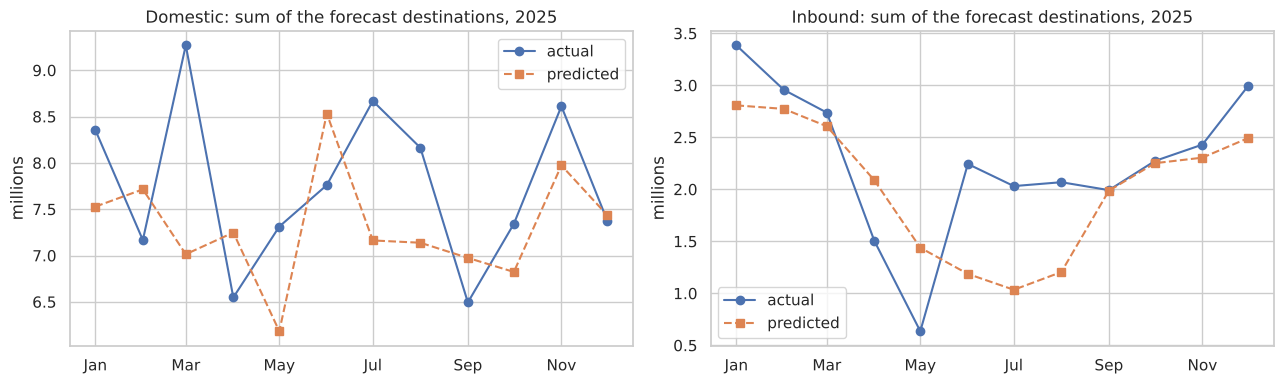

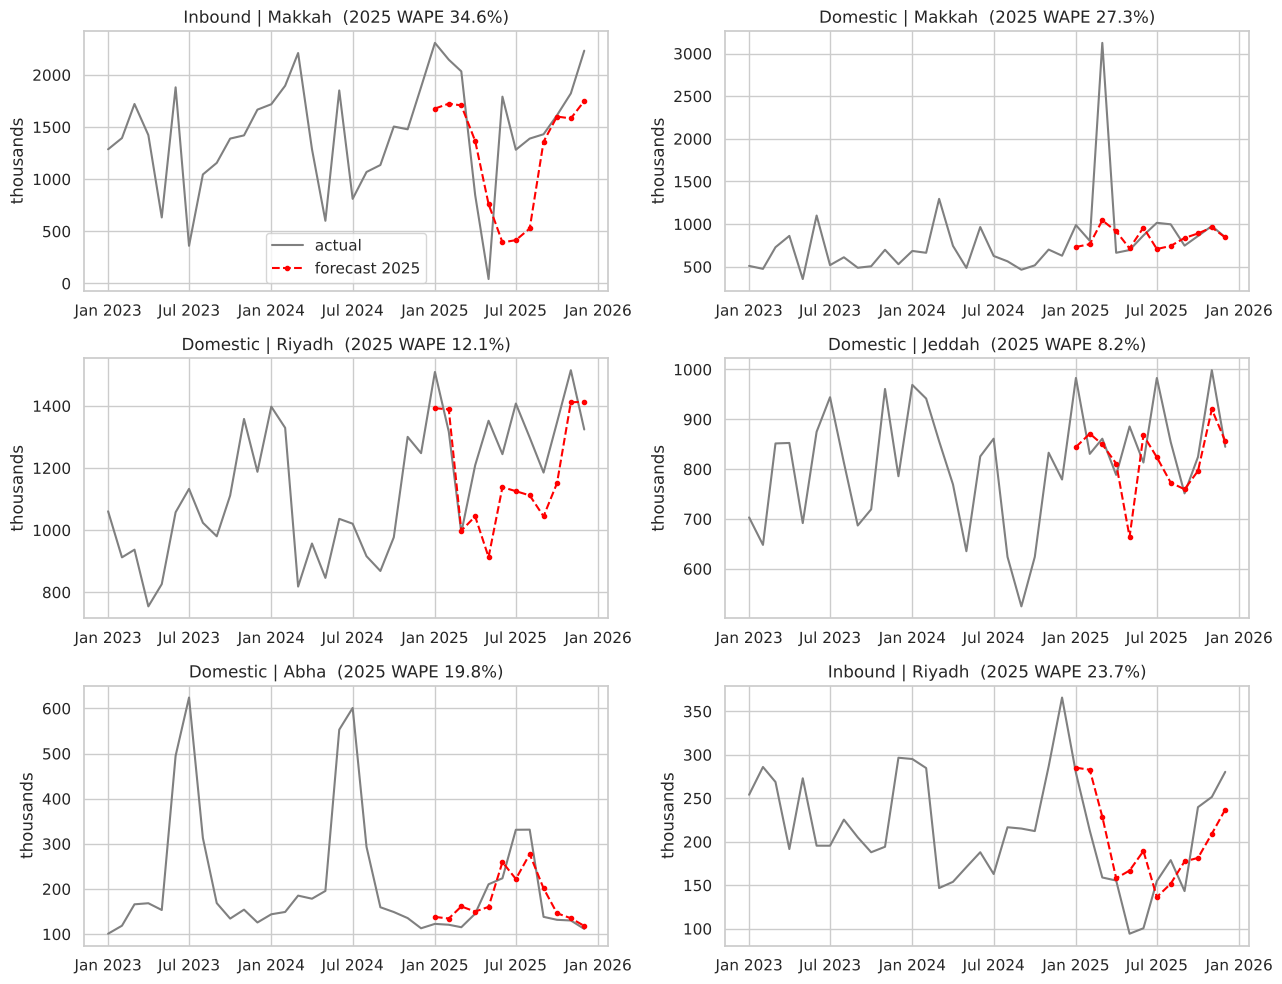

In [16]:
P = TEST_PREDS[SELECTED]
nat = P.groupby(["tourist_type", "date"])[["tourists", "pred"]].sum().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (typ, g) in zip(axes, nat.groupby("tourist_type")):
    ax.plot(g.date, g.tourists / 1e6, marker="o", label="actual")
    ax.plot(g.date, g.pred / 1e6, marker="s", ls="--", label="predicted")
    ax.set_title(f"{typ}: sum of the forecast destinations, 2025"); ax.set_ylabel("millions"); ax.legend()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.savefig(FIG / "03_test_national.png", dpi=200); plt.show()

show = ["Inbound | Makkah", "Domestic | Makkah", "Domestic | Riyadh",
        "Domestic | Jeddah", "Domestic | Abha", "Inbound | Riyadh"]
hist = feat[(feat.date >= "2023-01-01")]
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, s in zip(axes.ravel(), show):
    h = hist[hist.series == s]; p = P[P.series == s]
    ax.plot(h.date, h.tourists / 1e3, color="grey", label="actual")
    ax.plot(p.date, p.pred / 1e3, color="red", marker="o", ms=3, ls="--", label="forecast 2025")
    w = t.regression_metrics(p.tourists, p.pred)["WAPE_%"]
    ax.set_title(f"{s}  (2025 WAPE {w:.1f}%)"); ax.set_ylabel("thousands")
    ax.xaxis.set_major_locator(mdates.MonthLocator([1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0, 0].legend(); plt.tight_layout(); plt.savefig(FIG / "03_test_series.png", dpi=200); plt.show()

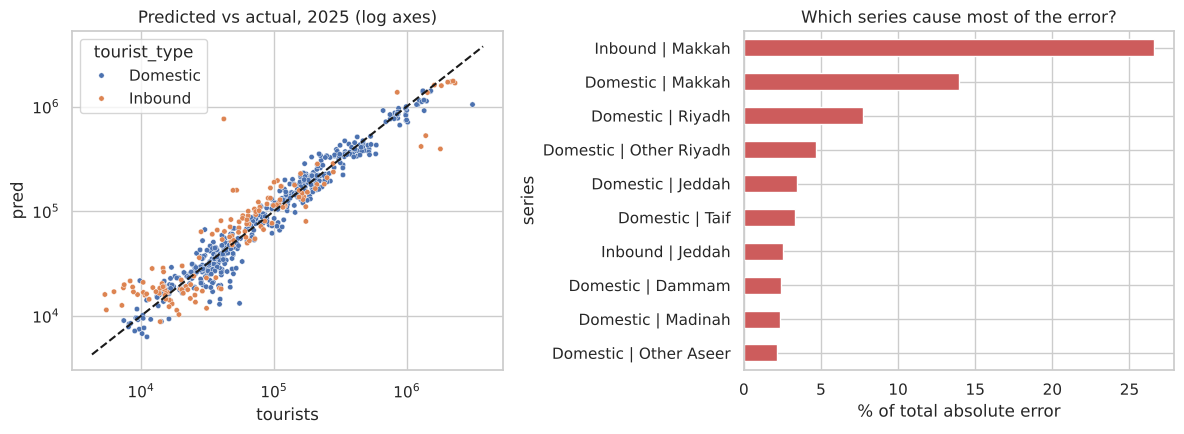

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=P, x="tourists", y="pred", hue="tourist_type", s=15, ax=axes[0])
lim = [P[["tourists", "pred"]].min().min() * 0.8, P[["tourists", "pred"]].max().max() * 1.2]
axes[0].plot(lim, lim, "k--"); axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual, 2025 (log axes)")
P = P.assign(abs_err=(P.pred - P.tourists).abs())
contrib = (P.groupby("series")["abs_err"].sum() / P["abs_err"].sum() * 100).nlargest(10)
contrib.sort_values().plot.barh(ax=axes[1], color="indianred")
axes[1].set_xlabel("% of total absolute error"); axes[1].set_title("Which series cause most of the error?")
plt.tight_layout(); plt.savefig(FIG / "03_test_errors.png", dpi=200); plt.show()
P.drop(columns="abs_err").to_csv(OUT / "test_predictions_selected_model.csv", index=False)

## 11. What did the models learn? (interpretation)
* **Linear Regression:** the standardised coefficients show how much log(tourists)
  changes when a feature increases by one standard deviation.
* **Random Forest:** `feature_importances_` measures how much each feature reduced the
  squared error over all splits of all trees (larger = used more and more usefully).
Both models are fitted on the development data (2022-2024) only.

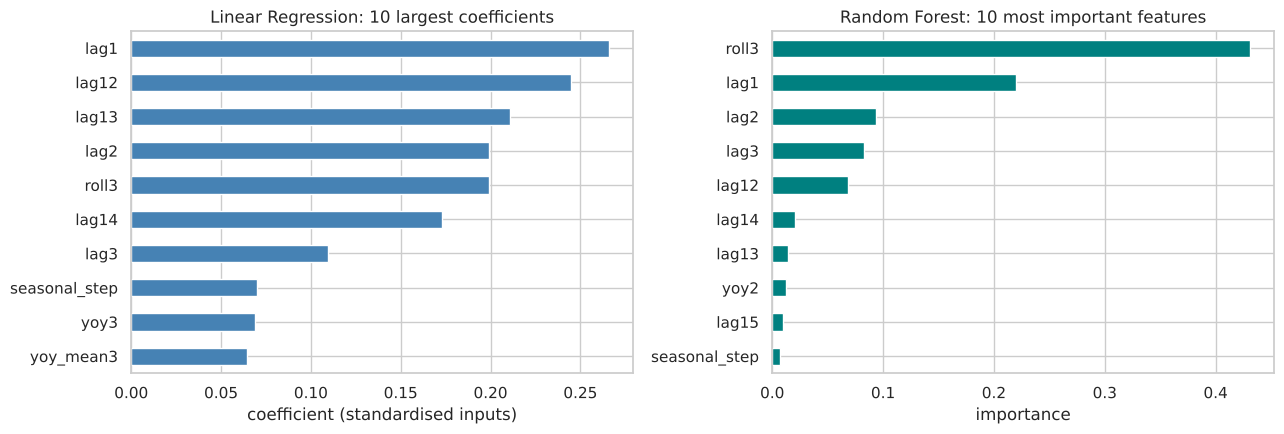

In [18]:
lin_name = finalists.loc[finalists.family == "Linear Regression", "model"].item()
rf_name = finalists.loc[finalists.family == "Random Forest", "model"].item()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
spec = SPECS[lin_name]
lin = make_pipeline(LinearRegression(), spec["features"]).fit(dev[spec["features"]], dev["log_y"])
coef = pd.Series(lin.named_steps["model"].coef_, index=lin.named_steps["prep"].get_feature_names_out())
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
coef.reindex(coef.abs().sort_values().index).tail(10).plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title(f"Linear Regression: 10 largest coefficients"); axes[0].set_xlabel("coefficient (standardised inputs)")
spec = SPECS[rf_name]
rf = make_pipeline(spec["estimator"](), spec["features"], scale=False).fit(dev[spec["features"]], dev["log_y"])
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=rf.named_steps["prep"].get_feature_names_out())
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
imp.sort_values().tail(10).plot.barh(ax=axes[1], color="teal")
axes[1].set_title("Random Forest: 10 most important features"); axes[1].set_xlabel("importance")
plt.tight_layout(); plt.savefig(FIG / "03_feature_importance.png", dpi=200); plt.show()

## 12. Course link: linear regression by gradient descent
To show what `LinearRegression.fit` does, we minimise the MSE of a small model
(3 standardised features) ourselves with **gradient descent**:
`w <- w - learning_rate * gradient`, with a stopping tolerance and a maximum number of
iterations. The result should match scikit-learn's exact least-squares solution.

Gradient descent stopped after 348 iterations, final MSE 0.36965
GD weights:      [11.1372  0.7385  0.6767  0.1409]
sklearn weights: [11.1372  0.7385  0.6767  0.1409]


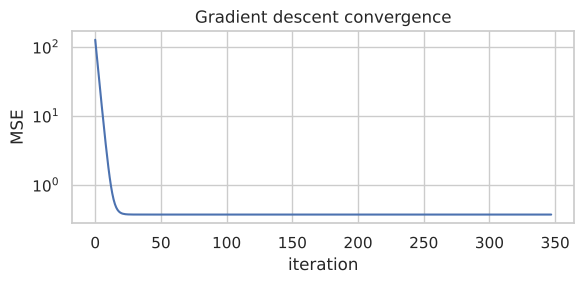

In [19]:
cols = ["lag1", "lag12", "yoy_mean3"]
X = dev[cols].to_numpy(); y = dev["log_y"].to_numpy()
mu, sd = X.mean(axis=0), X.std(axis=0); Xs = (X - mu) / sd          # standardise (training data)
Xb = np.c_[np.ones(len(Xs)), Xs]                                     # add intercept column
w = np.zeros(Xb.shape[1]); lr, tol, losses = 0.1, 1e-12, []
for it in range(20_000):
    err = Xb @ w - y
    losses.append((err ** 2).mean())                                 # MSE loss
    grad = 2 / len(y) * Xb.T @ err                                   # gradient of MSE
    w -= lr * grad                                                   # update step
    if it > 0 and abs(losses[-2] - losses[-1]) < tol:                # converged?
        break
sk = LinearRegression().fit(Xs, y)
print(f"Gradient descent stopped after {it + 1} iterations, final MSE {losses[-1]:.5f}")
print("GD weights:     ", np.round(w, 4))
print("sklearn weights:", np.round(np.r_[sk.intercept_, sk.coef_], 4))
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.yscale("log")
plt.xlabel("iteration"); plt.ylabel("MSE"); plt.title("Gradient descent convergence")
plt.tight_layout(); plt.savefig(FIG / "03_gradient_descent.png", dpi=200); plt.show()

In [20]:
# Final summary printed for the report
c = comparison.set_index("model")
for name in c.index:
    r = c.loc[name]
    print(f"{name}{'   <-- SELECTED' if r['selected'] else ''}")
    print(f"   CV WAPE {r['CV_WAPE_%']:.2f}% | train WAPE {r['Train_WAPE_%']:.2f}% | 2025 WAPE {r['Test_WAPE_%']:.2f}% "
          f"-> accuracy {r['Test_Accuracy_%']:.2f}% | national accuracy {r['National_Accuracy_%']:.2f}% | "
          f"MAE {r['Test_MAE']:.0f} | R2 {r['Test_R2']:.3f}")

Random Forest leaf=2 [all features]   <-- SELECTED
   CV WAPE 22.91% | train WAPE 9.57% | 2025 WAPE 20.50% -> accuracy 79.50% | national accuracy 86.44% | MAE 39522 | R2 0.850
PCA (90% variance) + Linear Regression [lags + holy-city, NO scaling]
   CV WAPE 23.44% | train WAPE 25.45% | 2025 WAPE 23.28% -> accuracy 76.72% | national accuracy 83.53% | MAE 44885 | R2 0.818
Linear Regression [all lags]
   CV WAPE 24.42% | train WAPE 25.68% | 2025 WAPE 22.25% -> accuracy 77.75% | national accuracy 84.35% | MAE 42903 | R2 0.815
Baseline: previous month
   CV WAPE 26.81% | train WAPE 31.48% | 2025 WAPE 22.83% -> accuracy 77.17% | national accuracy 82.38% | MAE 44015 | R2 0.743


## 13. Discussion: results, the 80% criterion and limitations
*(Numbers are from the executed run of this notebook; all random seeds are fixed.)*

**Validation (2023-2024, expanding-window CV):**

| Model family (best configuration) | CV WAPE | 2024 WAPE |
|---|---|---|
| Baseline: previous month | 26.81% | 25.78% |
| Linear Regression [all lags] | 24.42% | 22.44% |
| PCA (90%) + Linear Regression [lags + holy-city, no scaling] | 23.44% | 21.82% |
| **Random Forest, min_samples_leaf=2 [all features]** | **22.91%** | **18.48%** |

Random Forest was best and more than 0.5 points ahead of the next family, so the rule selected it.

**Final test (2025, one-month-ahead):**

| Model | Accuracy (100 - WAPE) | Domestic | Inbound | National level | MAE | R2 |
|---|---|---|---|---|---|---|
| **Random Forest (selected)** | **79.50%** | **83.36%** | 66.33% | **86.44%** | 39,522 | 0.85 |
| Linear Regression | 77.75% | 82.34% | 62.06% | 84.35% | 42,903 | 0.81 |
| PCA + Linear Regression | 76.72% | 80.99% | 62.15% | 83.53% | 44,885 | 0.82 |
| Baseline: previous month | 77.17% | 79.94% | 67.71% | 82.38% | 44,015 | 0.74 |

**What the experiments show**
* **Machine learning beats the baseline** on validation (22.9% vs. 26.8% WAPE). On 2025,
  Random Forest is better than the baseline overall, for domestic destinations and nationally.
  For inbound destinations the simple baseline (67.7%) is slightly better than every model.
* **Linear Regression and feature selection:** using the calendar features for every
  destination made Linear Regression much worse (34.1% vs. 24.4%). One Ramadan coefficient
  cannot fit Makkah (big effect) and Riyadh (no effect) at the same time; the model fits noise
  (overfitting). Restricting them to holy cities removed the damage but did not improve the
  lag-only model (24.58% vs. 24.42%).
* **PCA:** with the lag + holy-city features, keeping 4-9 of 16 components improved
  validation error (23.4-23.9% vs. 24.6% without PCA), because the components remove the
  strong correlation between lags. With all features (including one-hot provinces) PCA made
  things worse (26.3-27.4%). On 2025 the PCA model did **not** keep its advantage
  (76.72% vs. 77.75%), so a validation improvement of about 1 point is within normal variation.
* **Normalisation:** PCA without scaling was slightly better here (23.44% vs. 23.66%). Most
  inputs are already on the same log scale, so scaling matters less than usual. It still
  matters in general, because PCA follows the features with the largest variance.
* **Random Forest** gained most on the 2024 folds (18.5% vs. 22.4% for Linear Regression),
  where more training data were available. Its training error (9.6%) is much lower than its
  test error (20.5%), which is a sign of overfitting. Averaging 300 trees limits the damage,
  but larger leaves (`min_samples_leaf=5`) are a safer alternative with similar validation error (23.6%).

**Does the project reach the rubric's 80%?** The selected model reaches **79.50%** over all
destination-months: just below 80%. It reaches **83.4% for domestic destinations** and
**86.4% at national level**. Inbound destinations (66%) pull the total down, because Umrah
and Hajj flows shift with the lunar calendar and small destinations have noisy survey counts.
We report the result as it is instead of choosing a metric that would pass 80%.

**Limitations**
1. Short history: 2021 is COVID-affected, and lags need 15 months, so training starts in April 2022.
2. City-level survey estimates have a larger margin of error (workbook Metadata).
3. Only 52 of 82 series are fully observed. The excluded inbound series are small (~5% of inbound tourists).
4. This is one-month-ahead forecasting with the previous months known, not a 12-month-ahead plan.
5. Ramadan/Hajj dates are typed into `src/tourism.py`, and the pre-Hajj window is approximated as 30 days.
6. **Transparency:** an earlier version of this notebook also tested Ridge regression,
   Gradient Boosting and an ensemble on 2025. The model set was then reduced to course
   methods plus Random Forest, so that every method can be explained. Because the 2025 results
   of the earlier models had already been seen, the test score is slightly less independent
   than a single untouched evaluation.
   The pre-Hajj feature idea also came from error analysis that displayed 2025 values;
   the same May drop is visible in 2023 and 2024.